Q-1. Equilibrium conversion checker


In a liquid-phase reactor the reaction A + B arrow C reaches equilibrium. Initial concentration are [A]o = 1.0, [B]o=1.0 and [C]o = 0 mol/L of C is formed ,Kc = x/(1-x)^2, which rearranges to the quadratic equation Kcmultiplyx^2-(2Kc +1 )multiply + Kc = 0
Write a Python program that:
a)reads Kc using input(), prints the data type of he raw input and the converted value, and shows a clear messege(no crash) if the text is not a number or if Kc<=0
 b)find a,b,c the disciminant and both roots 
 c)selects the physically meaningfull root (0<=x<=1)
  d)prints equilibrium A,B,C and the conversion of the limiting reactant = x/[A]*100(%)
   e)classifies the conversion using if/elif/else >= 70% "high", 40% "moderate", otherwise "low" Test with Kc=4, Kc=0.5 Kc=abc Kc=-2

In [16]:
# Liquid-phase equilibrium A + B <-> C
A0 = 1.0
B0 = 1.0
C0 = 0.0


def analyze_equilibrium(raw_kc):
    print("Raw input data type:", type(raw_kc).__name__)

    try:
        Kc = float(raw_kc)
        print("Converted Kc data type:", type(Kc).__name__)
        print("Converted Kc:", Kc)

        if Kc <= 0:
            print("Error: Kc must be greater than 0.")
            return

        a = Kc
        b = -(2 * Kc + 1)
        c = Kc

        discriminant = b**2 - 4*a*c

        print("a =", a)
        print("b =", b)
        print("c =", c)
        print("Discriminant =", discriminant)

        if discriminant < 0:
            print("No real roots; no physically meaningful equilibrium conversion.")
            return

        sqrt_discriminant = discriminant ** 0.5
        root1 = (-b + sqrt_discriminant) / (2*a)
        root2 = (-b - sqrt_discriminant) / (2*a)

        print("Root 1:", root1)
        print("Root 2:", root2)

        physical_roots = [root for root in (root1, root2)
                          if 0 <= root <= 1]

        if not physical_roots:
            print("No physical root in the range 0 <= x <= 1.")
            return

        x = physical_roots[0]
        equilibrium_A = A0 - x
        equilibrium_B = B0 - x
        equilibrium_C = C0 + x
        conversion_percent = (x / A0) * 100

        print("Equilibrium [A] =", equilibrium_A, "mol/L")
        print("Equilibrium [B] =", equilibrium_B, "mol/L")
        print("Equilibrium [C] =", equilibrium_C, "mol/L")
        print("Conversion of limiting reactant =",
              conversion_percent, "%")

        if conversion_percent >= 70:
            classification = "high"
        elif conversion_percent >= 40:
            classification = "moderate"
        else:
            classification = "low"

        print("Conversion classification:", classification)

    except ValueError:
        print("Error: The input is not a number.")


raw_kc = input("Enter Kc: ")
analyze_equilibrium(raw_kc)


Raw input data type: str
Converted Kc data type: float
Converted Kc: 0.5
a = 0.5
b = -2.0
c = 0.5
Discriminant = 3.0
Root 1: 3.732050807568877
Root 2: 0.2679491924311228
Equilibrium [A] = 0.7320508075688772 mol/L
Equilibrium [B] = 0.7320508075688772 mol/L
Equilibrium [C] = 0.2679491924311228 mol/L
Conversion of limiting reactant = 26.794919243112282 %
Conversion classification: low


Test with Kc= 4, kc=0.5,kc=abc and Kc=-2

In [3]:
print("Test cases")
for test_value in ("4", "0.5", "abc", "-2"):
    print("\n--- Kc input:", test_value, "---")
    analyze_equilibrium(test_value)


Test cases

--- Kc input: 4 ---
Raw input data type: str
Converted Kc data type: float
Converted Kc: 4.0
a = 4.0
b = -9.0
c = 4.0
Discriminant = 17.0
Root 1: 1.6403882032022077
Root 2: 0.6096117967977924
Equilibrium [A] = 0.3903882032022076 mol/L
Equilibrium [B] = 0.3903882032022076 mol/L
Equilibrium [C] = 0.6096117967977924 mol/L
Conversion of limiting reactant = 60.96117967977924 %
Conversion classification: moderate

--- Kc input: 0.5 ---
Raw input data type: str
Converted Kc data type: float
Converted Kc: 0.5
a = 0.5
b = -2.0
c = 0.5
Discriminant = 3.0
Root 1: 3.732050807568877
Root 2: 0.2679491924311228
Equilibrium [A] = 0.7320508075688772 mol/L
Equilibrium [B] = 0.7320508075688772 mol/L
Equilibrium [C] = 0.2679491924311228 mol/L
Conversion of limiting reactant = 26.794919243112282 %
Conversion classification: low

--- Kc input: abc ---
Raw input data type: str
Error: The input is not a number.

--- Kc input: -2 ---
Raw input data type: str
Converted Kc data type: float
Converted 

Q-2 Batch reactor simulation and batch tracking

PartA
 A batch reactor decomposes reactant A (A-> products) by a first order reaction dC/dT=-kC. Use the Euler method: C_new = C_oldk*C_old △t. Take c=2mol/L k=0.08/min △t=1min 1)using a for loop simulate 10 minutes and print a table of time,concentration and conversion. 2)using math.exp(), calculate the exact value Ce to power (-kt) at 10 min and print the absolute error of the euler result. 3)Using a while loop repeat the simulation until conversion reaches 60% or time reaches 100 min. Print the time needed and the final concentration. 

In [6]:
import math

# Part A: Euler simulation for the first 10 minutes
C0 = 2.0
k = 0.08
DT = 1.0

C = C0
time = 0.0

print("Time (min)  Concentration (mol/L)  Conversion (%)")
for minute in range(11):
    conversion = (C0 - C) / C0 * 100
    print(f"{minute:8d}  {C:24.6f}  {conversion:15.2f}")

    if minute < 10:
        C = C - k * C * DT

# Exact concentration and absolute Euler error at 10 minutes
C_exact = C0 * math.exp(-k * 10)
absolute_error = abs(C - C_exact)

print("\nAt 10 min:")
print("Euler concentration:", round(C, 8), "mol/L")
print("Exact concentration:", round(C_exact, 8), "mol/L")
print("Absolute error:", round(absolute_error, 8), "mol/L")

# Repeat with a while loop until conversion reaches 60% or 100 minutes
C = C0
time = 0.0
conversion = 0.0

while conversion < 60 and time < 100:
    C = C - k * C * DT
    time += DT
    conversion = (C0 - C) / C0 * 100

print("\n60% conversion target simulation:")
print("Time needed:", time, "min")
print("Final concentration:", round(C, 8), "mol/L")


Time (min)  Concentration (mol/L)  Conversion (%)
       0                  2.000000             0.00
       1                  1.840000             8.00
       2                  1.692800            15.36
       3                  1.557376            22.13
       4                  1.432786            28.36
       5                  1.318163            34.09
       6                  1.212710            39.36
       7                  1.115693            44.22
       8                  1.026438            48.68
       9                  0.944323            52.78
      10                  0.868777            56.56

At 10 min:
Euler concentration: 0.86877691 mol/L
Exact concentration: 0.89865793 mol/L
Absolute error: 0.02988102 mol/L

60% conversion target simulation:
Time needed: 11.0 min
Final concentration: 0.79927476 mol/L


PartB. Batch lables such as PLANT20261030 are stored as text. Write a program that reads a lable,m loops through each character and prints the number of digits and the sum of digits. Show a messege for an empty label and for a label with no digits. Test with PLANT20261030, an empty label and ABCDEF

In [5]:
# Part B: Batch label digit analyzer

def analyze_label(label):
    if label == "":
        print("Message: The label is empty.")
        return

    digit_count = 0
    digit_sum = 0

    for character in label:
        if character.isdigit():
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print("Message: The label contains no digits.")
    else:
        print("Number of digits:", digit_count)
        print("Sum of digits:", digit_sum)


label = input("Enter a batch label: ").strip()
print("\nInput label:", label if label else "<empty>")
print("Label analysis:")
analyze_label(label)

print("\nTest cases:")
for test_label in ("PLANT20261030", "", "ABCDEF"):
    print("Label:", test_label if test_label else "<empty>")
    analyze_label(test_label)



Input label: 3
Label analysis:
Number of digits: 1
Sum of digits: 3

Test cases:
Label: PLANT20261030
Number of digits: 8
Sum of digits: 14
Label: <empty>
Message: The label is empty.
Label: ABCDEF
Message: The label contains no digits.


Q-3 Additive screening and sampling schedule 

 PartA. A laboratory has n candidate additives and wants to test r of them togrther in one formulation (order does not matter). Write a recursive function factorial(n) (remember the base case for 0 ) and a function combination (n,r)=n!/(r!(n-r)) that uses it. Reject invalid input (negative values, r>n ). Print the number of possible formulations for n=6, r=3 and show the messege for n=5, r=7 .

In [7]:
def factorial(n):
    if n < 0:
        raise ValueError("n must not be negative")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0:
        return None, "Error: n and r must not be negative."
    if r > n:
        return None, "Error: r cannot be greater than n."

    count = factorial(n) // (factorial(r) * factorial(n - r))
    return count, None


count, message = combination(6, 3)
if message:
    print(message)
else:
    print("n = 6, r = 3")
    print("Number of possible formulations:", count)

count, message = combination(5, 7)
if message:
    print("n = 5, r = 7")
    print(message)


n = 6, r = 3
Number of possible formulations: 20
n = 5, r = 7
Error: r cannot be greater than n.


PartB. During a reaction, samples are taken at times = Fibonacci number*2. Write an Iterative function fib_iter(n) that returns a list of a first n fibonacci numbers and a recursive function fib_rec(k) that returns the k-th fibonacci number (F=0, F1=1) for n=10, check that both functions agree and print a table: Sample no. | Fibonacci tag | Sampling time (min)

In [9]:
def fib_iter(n):
    if n < 0:
        raise ValueError("n must not be negative")

    fibonacci_numbers = []
    a, b = 0, 1

    for _ in range(n):
        fibonacci_numbers.append(a)
        a, b = b, a + b

    return fibonacci_numbers


def fib_rec(k):
    if k < 0:
        raise ValueError("k must not be negative")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 10
iterative_values = fib_iter(n)
recursive_values = [fib_rec(k) for k in range(n)]

print("Both functions agree:", iterative_values == recursive_values)
print("Fibonacci values:", iterative_values)
print("\nSample no. | Fibonacci tag | Sampling time (min)")
print("-----------|---------------|-------------------")

for sample_no, fibonacci_tag in enumerate(iterative_values, start=1):
    sampling_time = fibonacci_tag * 2
    print(f"{sample_no:^11} | {fibonacci_tag:^13} | {sampling_time:^19}")


Both functions agree: True
Fibonacci values: [0, 1, 1, 2, 3, 5, 8, 13, 21, 34]

Sample no. | Fibonacci tag | Sampling time (min)
-----------|---------------|-------------------
     1      |       0       |          0         
     2      |       1       |          2         
     3      |       1       |          2         
     4      |       2       |          4         
     5      |       3       |          6         
     6      |       5       |         10         
     7      |       8       |         16         
     8      |      13       |         26         
     9      |      21       |         42         
    10      |      34       |         68         


Q-4.Kinetics and gas data:pandas and matplotlib

In [12]:
#pip installed pandas

Q.4. Kinetics and gas data: Pandas and matplotlib

 Hydrolysis of an ester was studied at two temperatures. the concentration (mol/L) was recorded: Time = (0,10,20,30,40,50) Run1_mol_L (Low T) = (1,00, 0.74, 0.55, 0.41, 0.30, 0.22) Run2-mol_L (high T) = (1.00, 0.61, 0.37, 0.22, 0.14, 0.08) a) Create a dataFrame from this table. Save it as kinetics.csv (without the index column) and as kinetics.json. Read the CSV back and print its shape and datatypes. b)Print the mean and standard deviation of Run1 and Run2 and state which run shows more vabration. c)Plot both runs on the graph (Time on X-axis) with title, axis labels with units, legend and grid. d)Nitrogen gas is compressed slowly in a piston cylinder at constant temperature: volume_L = (1,2,3,4,5) pressure_bar = (4.00, 2.03, 1.31, 1.02, 0.81) Plot pressure vs volume as a scater plot. Calculate k as the mean of P*V and drAw the reference curve p = k/V on the same graph. Add title, labels with units and legend.

In [14]:
def factorial(n):
    if not isinstance(n, int) or isinstance(n, bool) or n < 0:
        raise ValueError("n must be a non-negative integer.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if (
        not isinstance(n, int) or isinstance(n, bool)
        or not isinstance(r, int) or isinstance(r, bool)
        or n < 0 or r < 0 or r > n
    ):
        raise ValueError("Invalid input: require n >= 0 and 0 <= r <= n.")
    return factorial(n) // (factorial(r) * factorial(n - r))


print("Possible formulations for n=6, r=3:", combination(6, 3))

try:
    combination(5, 7)
except ValueError as error:
    print(error)


def fib_iter(n):
    if not isinstance(n, int) or isinstance(n, bool) or n < 0:
        raise ValueError("n must be a non-negative integer.")

    values = []
    first, second = 0, 1
    for _ in range(n):
        values.append(first)
        first, second = second, first + second
    return values


def fib_rec(k):
    if not isinstance(k, int) or isinstance(k, bool) or k < 0:
        raise ValueError("k must be a non-negative integer.")
    if k < 2:
        return k
    return fib_rec(k - 1) + fib_rec(k - 2)


fib_values = fib_iter(10)
agree = all(value == fib_rec(index) for index, value in enumerate(fib_values))
print("\nIterative and recursive results agree:", agree)
print("Sample no. | Fibonacci tag | Sampling time (min)")
for sample_no, fib_tag in enumerate(fib_values, start=1):
    print(f"{sample_no:>10} | {fib_tag:>13} | {fib_tag * 2}")

Possible formulations for n=6, r=3: 20
Invalid input: require n >= 0 and 0 <= r <= n.

Iterative and recursive results agree: True
Sample no. | Fibonacci tag | Sampling time (min)
         1 |             0 | 0
         2 |             1 | 2
         3 |             1 | 2
         4 |             2 | 4
         5 |             3 | 6
         6 |             5 | 10
         7 |             8 | 16
         8 |            13 | 26
         9 |            21 | 42
        10 |            34 | 68


CSV shape: (6, 3)
CSV data types:
Time_min         int64
Run1_Low_T     float64
Run2_High_T    float64
dtype: object

Run 1 mean: 0.5367
Run 1 standard deviation: 0.2928
Run 2 mean: 0.4033
Run 2 standard deviation: 0.3485
Run 2 (High T) shows more variation.


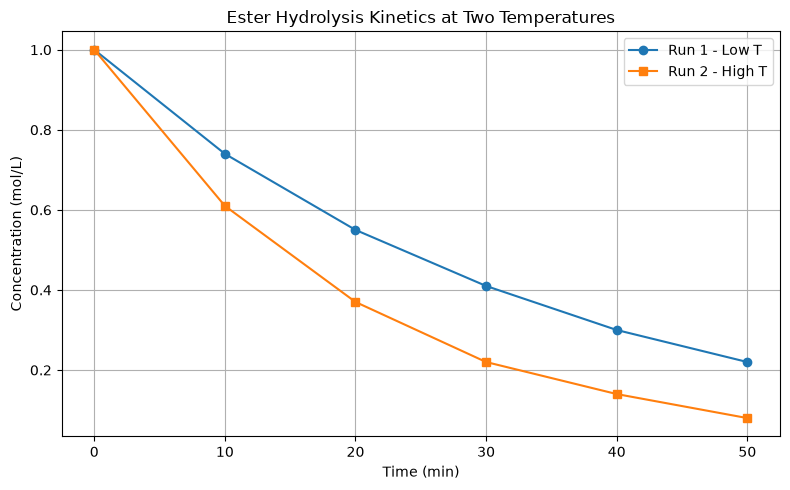


Mean pressure-volume constant k = 4.024 bar.L


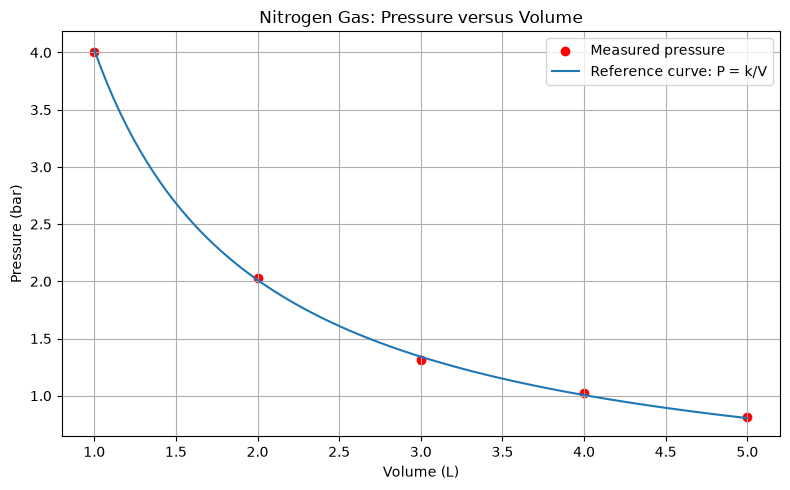

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# a) Create kinetics DataFrame, export it, and read it back
kinetics = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_Low_T": [1.00, 0.74, 0.55, 0.41, 0.30, 0.22],
    "Run2_High_T": [1.00, 0.61, 0.37, 0.22, 0.14, 0.08]
})

kinetics.to_csv("kinetics.csv", index=False)
kinetics.to_json("kinetics.json", orient="records")

kinetics_read = pd.read_csv("kinetics.csv")
print("CSV shape:", kinetics_read.shape)
print("CSV data types:")
print(kinetics_read.dtypes)

# b) Mean and standard deviation
run1_mean = kinetics["Run1_Low_T"].mean()
run1_std = kinetics["Run1_Low_T"].std()
run2_mean = kinetics["Run2_High_T"].mean()
run2_std = kinetics["Run2_High_T"].std()

print("\nRun 1 mean:", round(run1_mean, 4))
print("Run 1 standard deviation:", round(run1_std, 4))
print("Run 2 mean:", round(run2_mean, 4))
print("Run 2 standard deviation:", round(run2_std, 4))

if run1_std > run2_std:
    print("Run 1 (Low T) shows more variation.")
elif run2_std > run1_std:
    print("Run 2 (High T) shows more variation.")
else:
    print("Both runs show equal variation.")

# c) Kinetics plot
plt.figure(figsize=(8, 5))
plt.plot(kinetics["Time_min"], kinetics["Run1_Low_T"],
         marker="o", label="Run 1 - Low T")
plt.plot(kinetics["Time_min"], kinetics["Run2_High_T"],
         marker="s", label="Run 2 - High T")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.title("Ester Hydrolysis Kinetics at Two Temperatures")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# d) Pressure-volume plot
volume_L = np.array([1, 2, 3, 4, 5])
pressure_bar = np.array([4.00, 2.03, 1.31, 1.02, 0.81])

k = np.mean(pressure_bar * volume_L)
volume_curve = np.linspace(volume_L.min(), volume_L.max(), 100)
pressure_curve = k / volume_curve

print("\nMean pressure-volume constant k =", round(k, 4), "bar.L")

plt.figure(figsize=(8, 5))
plt.scatter(volume_L, pressure_bar, color="red",
            label="Measured pressure")
plt.plot(volume_curve, pressure_curve,
         label="Reference curve: P = k/V")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.title("Nitrogen Gas: Pressure versus Volume")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
